## Experimento histórico

Este notebook conserva los cálculos y salidas previos a la revisión temporal. No usar sus métricas como conclusiones finales. El flujo vigente está en `ML.train`, `protocol.json` y `ML_Resultados_Finales.ipynb`. Las fechas y etiquetas se unifican en `features.py`.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración de estilo visual para la tesis
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams['figure.dpi'] = 100  # Alta resolución para exportar imágenes

In [3]:
# Cargar datos y mostrar las primeras filas
df = pd.read_csv("./Datasets/train.csv")

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas\n")
print("Lista de columnas en tu dataset:")
print(df.columns.tolist())

df.head()

Dimensiones del dataset: 9800 filas y 18 columnas

Lista de columnas en tu dataset:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [4]:
# 1.1 Información general de columnas y tipos de datos
print("--- Información del Dataset ---")
df.info()

# 1.2 Revisar valores nulos por columna
print("\n--- Valores Nulos ---")
print(df.isnull().sum())

# 1.3 Verificar número de clientes únicos
print(f"\nTotal de clientes únicos: {df['Customer ID'].nunique()}")

--- Información del Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   

In [5]:
# 2.1 Convertir columnas de fecha a formato datetime
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%d/%m/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%d/%m/%Y')

# 2.2 Eliminar identificadores irrelevantes para el modelado
df_clean = df.drop(columns=['Row ID'])

# 2.3 Visualizar el rango de fechas analizado
print(f"Fecha mínima de orden: {df_clean['Order Date'].min()}")
print(f"Fecha máxima de orden: {df_clean['Order Date'].max()}")

Fecha mínima de orden: 2015-01-03 00:00:00
Fecha máxima de orden: 2018-12-30 00:00:00


In [6]:
# 3.1 Definir la fecha de observación (un día después de la última compra registrada)
snapshot_date = df_clean['Order Date'].max() + pd.Timedelta(days=1)

# 3.2 Agrupar por cliente para calcular Recencia, Frecuencia y Monto
rfm = df_clean.groupby('Customer ID').agg({
    'Order Date': lambda x: (snapshot_date - x.max()).days, # Recencia (días desde última compra)
    'Order ID': 'nunique',                                  # Frecuencia (órdenes únicas)
    'Sales': 'sum'                                          # Monto Total ($)
}).reset_index()

# 3.3 Renombrar columnas
rfm.columns = ['Customer_ID', 'Recency', 'Frequency', 'Monetary']
rfm.head()

,Customer_ID,Recency,Frequency,Monetary
0,AA-10315,185,5,5563.560
1,AA-10375,20,9,1056.390
2,AA-10480,260,4,1790.512
3,AA-10645,56,6,5086.935
4,AB-10015,416,3,886.156


In [7]:
# 4.1 Definir el umbral de Churn (ejemplo: cliente que no compra hace más de 180 días)
UMBRAL_DIAS = 180

# 1 = Abandono (Churn), 0 = Activo (Retenido)
rfm['Churn'] = (rfm['Recency'] > UMBRAL_DIAS).astype(int)

# 4.2 Distribución de la variable Churn
print("Distribución de Churn en el dataset:")
print(rfm['Churn'].value_counts(normalize=True) * 100)

Distribución de Churn en el dataset:
Churn
0    74.148802
1    25.851198
Name: proportion, dtype: float64


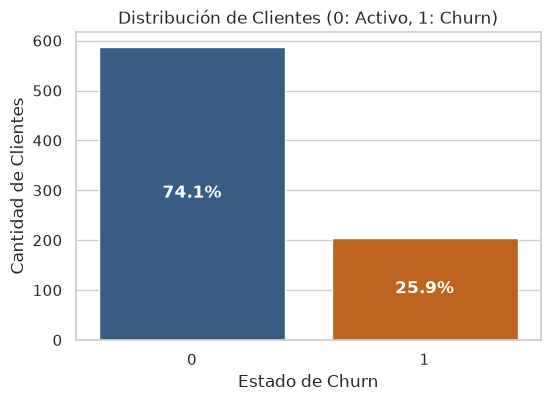

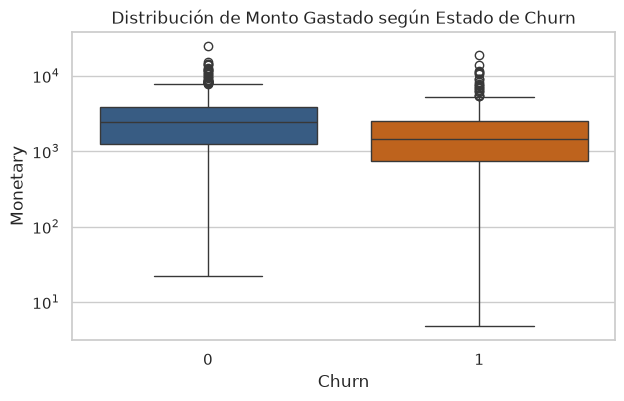

In [8]:
# 5.1 Gráfica de Distribución de Churn
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=rfm, x='Churn', hue='Churn', palette=['#2b5c8f', '#d95f02'], legend=False)
plt.title('Distribución de Clientes (0: Activo, 1: Churn)', fontsize=12)
plt.xlabel('Estado de Churn')
plt.ylabel('Cantidad de Clientes')

# Anotar porcentajes
total = len(rfm)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2, p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.savefig('evidencia_1_distribucion_churn.png', bbox_inches='tight')
plt.show()

# 5.2 Gráfica Boxplot de Monto por Churn
plt.figure(figsize=(7, 4))
sns.boxplot(data=rfm, x='Churn', y='Monetary', hue='Churn', palette=['#2b5c8f', '#d95f02'], legend=False)
plt.yscale('log')  # Escala logarítmica para manejar valores dispares
plt.title('Distribución de Monto Gastado según Estado de Churn')
plt.savefig('evidencia_2_boxplot_monetary.png', bbox_inches='tight')
plt.show()

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       118
           1       1.00      1.00      1.00        41

    accuracy                           1.00       159
   macro avg       1.00      1.00      1.00       159
weighted avg       1.00      1.00      1.00       159



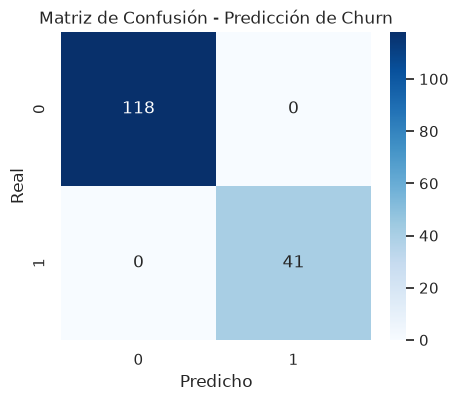

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split

# 6.1 Separar variables independientes (X) y target (y)
X = rfm[['Recency', 'Frequency', 'Monetary']]
y = rfm['Churn']

# 6.2 División Train/Test (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# 6.3 Entrenamiento del Modelo Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 6.4 Predicciones y Evaluación
y_pred = model.predict(X_test)

print("--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))

# 6.5 Matriz de Confusión
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión - Predicción de Churn')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.savefig('evidencia_3_matriz_confusion.png', bbox_inches='tight')
plt.show()

--- Reporte de Clasificación Corregido (Sin Data Leakage) ---
              precision    recall  f1-score   support

           0       0.77      0.98      0.86       118
           1       0.75      0.15      0.24        41

    accuracy                           0.77       159
   macro avg       0.76      0.56      0.55       159
weighted avg       0.76      0.77      0.70       159

ROC-AUC Score: 0.7338


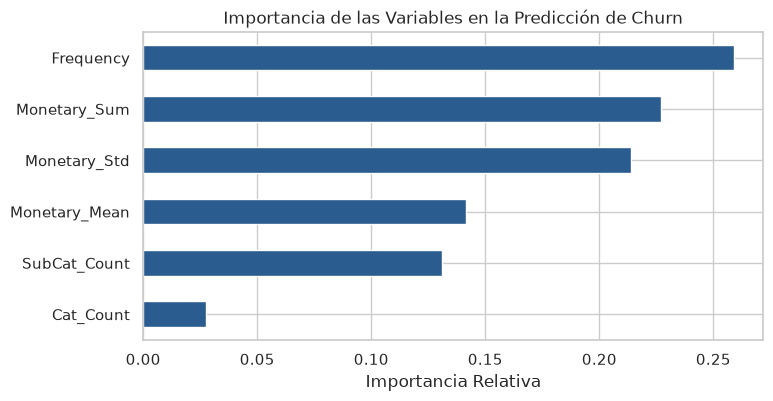

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# 1. Crear características avanzadas a nivel de cliente (Feature Engineering)
# Calculamos métricas históricas excluyendo la Recencia directa
rfm_features = df_clean.groupby('Customer ID').agg({
    'Order ID': 'nunique',                   # Frecuencia total
    'Sales': ['sum', 'mean', 'std'],         # Monto total, promedio y desviación
    'Category': 'nunique',                   # Variedad de categorías compradas
    'Sub-Category': 'nunique'                # Variedad de subcategorías
})

# Aplanar nombres de columnas
rfm_features.columns = ['Frequency', 'Monetary_Sum', 'Monetary_Mean', 'Monetary_Std', 'Cat_Count', 'SubCat_Count']
rfm_features['Monetary_Std'] = rfm_features['Monetary_Std'].fillna(0)

# Re-incorporar la variable Churn construida previamente en la tabla rfm
rfm_features['Churn'] = rfm['Churn'].values

# 2. Definir variables independientes (X) EXCLUYENDO Recency
X_valid = rfm_features.drop(columns=['Churn'])
y_valid = rfm_features['Churn']

# 3. División Train/Test con datos corregidos
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
    X_valid, y_valid, test_size=0.20, random_state=42, stratify=y_valid
)

# 4. Entrenamiento del Modelo Corregido
model_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model_rf.fit(X_train_v, y_train_v)

# 5. Predicción y Evaluación Realista
y_pred_v = model_rf.predict(X_test_v)
y_proba_v = model_rf.predict_proba(X_test_v)[:, 1]

print("--- Reporte de Clasificación Corregido (Sin Data Leakage) ---")
print(classification_report(y_test_v, y_pred_v))
print(f"ROC-AUC Score: {roc_auc_score(y_test_v, y_proba_v):.4f}")

# 6. Gráfica de Importancia de Características (Feature Importance)
plt.figure(figsize=(8, 4))
feature_importances = pd.Series(model_rf.feature_importances_, index=X_valid.columns).sort_values()
feature_importances.plot(kind='barh', color='#2b5c8f')
plt.title('Importancia de las Variables en la Predicción de Churn')
plt.xlabel('Importancia Relativa')
plt.savefig('evidencia_4_feature_importance.png', bbox_inches='tight')
plt.show()

In [12]:

import joblib
import pandas as pd

# ==============================================================================
# 1. GUARDAR EL MODELO ENTRENADO Y SUS DEPENDENCIAS (.pkl / .joblib)
# ==============================================================================

# Nombre del archivo para el modelo serializado
model_filename = 'modelo_churn_rf.pkl'

# Guardar el modelo en disco
joblib.dump(model_rf, model_filename)
print(f"✔️ Modelo de Machine Learning guardado exitosamente como: '{model_filename}'")


# ==============================================================================
# 2. GENERAR PROBABILIDADES DE CHURN PARA EL UNIVERSO DE CLIENTES
# ==============================================================================

# Calcular la probabilidad de Churn (Clase 1: Abandono) para TODOS los clientes
rfm_features['Churn_Probability'] = model_rf.predict_proba(X_valid)[:, 1]

# Redondear la probabilidad a 4 decimales
rfm_features['Churn_Probability'] = rfm_features['Churn_Probability'].round(4)

# Categorizar el nivel de riesgo para la toma de decisiones comerciales en el CRM
def categorizar_riesgo(prob):
    if prob >= 0.70:
        return 'Alto'
    elif prob >= 0.35:
        return 'Medio'
    else:
        return 'Bajo'

rfm_features['Riesgo_Fuga'] = rfm_features['Churn_Probability'].apply(categorizar_riesgo)


# ==============================================================================
# 3. EXPORTAR DATOS EN FORMATOS COMPATIBLES CON CRM OPEN SOURCE (.csv y .json)
# ==============================================================================

# Preparar la tabla final uniendo identificadores con métricas clave
crm_export_df = rfm_features.reset_index()[
    ['Customer ID', 'Frequency', 'Monetary_Sum', 'Churn_Probability', 'Riesgo_Fuga']
]

# Renombrar columnas a formato amigable para esquemas de base de datos CRM
crm_export_df.columns = [
    'customer_id', 
    'frecuencia_compras', 
    'monto_total_gastado', 
    'probabilidad_churn', 
    'categoria_riesgo'
]

# A) Exportar a CSV (ideal para importación masiva por lotes / ETL)
csv_filename = 'predicciones_crm_churn.csv'
crm_export_df.to_csv(csv_filename, index=False, encoding='utf-8')
print(f"✔️ Archivo CSV para importación CRM guardado como: '{csv_filename}'")

# B) Exportar a JSON (ideal para APIs REST / Flask / FastAPI)
json_filename = 'predicciones_crm_churn.json'
crm_export_df.to_json(json_filename, orient='records', indent=4, force_ascii=False)
print(f"✔️ Archivo JSON para consumo via API guardado como: '{json_filename}'")

# Visualizar las primeras 5 filas del archivo preparado para el CRM
crm_export_df.head()

✔️ Modelo de Machine Learning guardado exitosamente como: 'modelo_churn_rf.pkl'
✔️ Archivo CSV para importación CRM guardado como: 'predicciones_crm_churn.csv'
✔️ Archivo JSON para consumo via API guardado como: 'predicciones_crm_churn.json'


,customer_id,frecuencia_compras,monto_total_gastado,probabilidad_churn,categoria_riesgo
0,AA-10315,5,5563.560,0.3832,Medio
1,AA-10375,9,1056.390,0.1133,Bajo
2,AA-10480,4,1790.512,0.4312,Medio
3,AA-10645,6,5086.935,0.1552,Bajo
4,AB-10015,3,886.156,0.4616,Medio
